# Week 1 - Linear Regression 1
## Dataset: FEMA NFIP Claims

This week covers the basics of linear regression, with polynomial terms, interaction terms, multicollinearity and the variance inflation factor (VIF), and the difference between continuous and categorical features. The question for the NFIP data is how much of the size of a 2017 flood claim can be explained by information about the building, the policy, and the flood, before anyone looks at the damage estimate.

Module B already showed that building damage predicts the payout almost perfectly, which makes sense but does not explain anything, since damage and payout are two views of the same loss. So every damage and payout field is left out here. The model has to work from things like water depth, the value of the building, its coverage, whether it is elevated, where it is, and which storm hit it. That lines up with the Capstone proposal's goal of explaining claim severity from drivers that exist apart from the claim itself.

In [1]:
import time
import warnings
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings('ignore', category=FutureWarning)

df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] > 0)].copy()
print('2017 claims with a positive building payout:', len(df))

2017 claims with a positive building payout: 110352


### Target and features

The target is the base-10 log of the building payout, for the 2017 claims that paid something on the building. The raw payout is heavily right-skewed (skewness 3.78), and a linear model fit on raw dollars would spend most of its effort on the few largest claims. On the log scale the skewness drops to -0.98, and a coefficient reads as a percentage change in payout instead of a fixed dollar amount.

The continuous features are recorded water depth in the building (capped at 15, because deeper values are sparse and include obvious entry errors such as 610), the logs of building replacement cost and building coverage, number of floors, construction year, latitude, and longitude. Two are yes or no indicators, elevated building and primary residence. Three are categorical, with more than two levels.

- **Flood zone**, grouped into A zones, V zones (coastal high hazard), and X or everything else.
- **Storm**, from the `floodEvent` field, grouped into Hurricane Harvey, Hurricane Irma, and all other 2017 flooding.
- **Cause of damage**, from the NFIP code for how the water got in. The four groups are accumulation of rainfall, stream, river, or lake overflow, tidal water overflow, and other causes.

The summary tables already show that the categories matter. The median Harvey claim paid $73,853, about three and a half times the median Irma claim ($20,840), and claims caused by tidal water paid less than half as much as those caused by river overflow.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['floodZone'] = np.where(zone_letter.isin(['A', 'V']), zone_letter + ' zone', 'X or other zone')
df['storm'] = df['floodEvent'].where(df['floodEvent'].isin(['Hurricane Harvey', 'Hurricane Irma']),
                                     'Other 2017 flooding')
cause_names = {'1': 'Tidal water overflow', '2': 'Stream, river, or lake overflow',
               '4': 'Accumulation of rainfall', '0': 'Other causes'}
df['cause'] = df['causeOfDamage'].map(cause_names).fillna('Other causes')

needed = ['waterDepth', 'buildingReplacementCost', 'totalBuildingInsuranceCoverage',
          'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator', 'primaryResidenceIndicator',
          'constructionYear', 'latitude', 'longitude']
data = df.dropna(subset=needed).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)

data['logPayout'] = np.log10(data['amountPaidOnBuildingClaim'])
data['depth'] = data['waterDepth'].clip(-2, 15)
data['logReplacementCost'] = np.log10(data['buildingReplacementCost'].clip(lower=1))
data['logCoverage'] = np.log10(data['totalBuildingInsuranceCoverage'].clip(lower=1))
data['floors'] = data['numberOfFloorsInTheInsuredBuilding']

continuous = ['depth', 'logReplacementCost', 'logCoverage', 'floors', 'constructionYear', 'latitude', 'longitude']
binary = ['elevatedBuildingIndicator', 'primaryResidenceIndicator']
categorical = ['floodZone', 'storm', 'cause']

print('Claims used:', len(data), f"| median building payout: ${data['amountPaidOnBuildingClaim'].median():,.0f}")
print()
for col in categorical:
    summary = data.groupby(col)['amountPaidOnBuildingClaim'].agg(claims='size', median_payout='median')
    summary['median_payout'] = summary['median_payout'].map('${:,.0f}'.format)
    print(summary.sort_values('claims', ascending=False).to_string())
    print()

Claims used: 100625 | median building payout: $55,672

                 claims median_payout
floodZone                            
A zone            57064       $51,675
X or other zone   42476       $61,601
V zone             1085       $18,487

                     claims median_payout
storm                                    
Hurricane Harvey      70249       $73,853
Hurricane Irma        18942       $20,840
Other 2017 flooding   11434       $15,421

                                 claims median_payout
cause                                                
Accumulation of rainfall          41051       $57,669
Stream, river, or lake overflow   28554       $64,251
Other causes                      23246       $50,790
Tidal water overflow               7774       $29,028



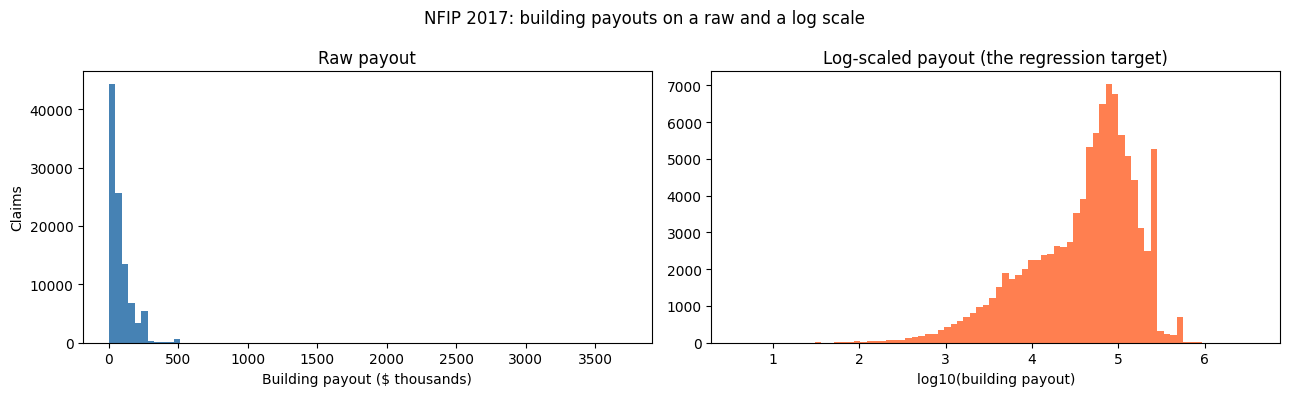

Skewness of raw payout: 3.78 | skewness of log payout: -0.98


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(data['amountPaidOnBuildingClaim'] / 1000, bins=80, color='steelblue')
axes[0].set_xlabel('Building payout ($ thousands)')
axes[0].set_ylabel('Claims')
axes[0].set_title('Raw payout')
axes[1].hist(data['logPayout'], bins=80, color='coral')
axes[1].set_xlabel('log10(building payout)')
axes[1].set_title('Log-scaled payout (the regression target)')
fig.suptitle('NFIP 2017: building payouts on a raw and a log scale')
plt.tight_layout()
plt.show()
print('Skewness of raw payout:', round(data['amountPaidOnBuildingClaim'].skew(), 2),
      '| skewness of log payout:', round(data['logPayout'].skew(), 2))

In [4]:
y = data['logPayout'].values
train_idx, test_idx = train_test_split(np.arange(len(data)), test_size=0.25, random_state=0)
kfold = KFold(n_splits=5, shuffle=True, random_state=0)
print('Training claims:', len(train_idx), '| test claims:', len(test_idx))


def evaluate(name, X, model=None):
    """Training, 5-fold cross-validated, and test R-squared for one feature set."""
    model = model if model is not None else LinearRegression()
    cv_r2 = cross_val_score(model, X.iloc[train_idx], y[train_idx], cv=kfold, scoring='r2').mean()
    model.fit(X.iloc[train_idx], y[train_idx])
    pred_train, pred_test = model.predict(X.iloc[train_idx]), model.predict(X.iloc[test_idx])
    return {'Model': name, 'Columns': X.shape[1],
            'Train R2': r2_score(y[train_idx], pred_train), 'CV R2': cv_r2,
            'Test R2': r2_score(y[test_idx], pred_test),
            'Test RMSE (log10)': mean_squared_error(y[test_idx], pred_test) ** 0.5}

Training claims: 75468 | test claims: 25157


### Continuous features first

The first model uses only the seven continuous features and the two yes or no indicators. Because the target is log10 of the payout, each coefficient converts to a percentage change with $10^{\beta} - 1$.

In [5]:
X_cont = data[continuous + binary].astype(float)
results = [evaluate('Continuous and yes/no features only', X_cont)]
base_model = LinearRegression().fit(X_cont.iloc[train_idx], y[train_idx])
coefs = pd.Series(base_model.coef_, index=X_cont.columns)
print(pd.DataFrame(results).round(4).to_string(index=False))
print()
print('Coefficients (change in log10 payout per unit, and the matching % change in payout):')
print(pd.DataFrame({'coef': coefs, '% change in payout': (10 ** coefs - 1) * 100}).round(3).to_string())

                              Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
Continuous and yes/no features only        9    0.2633 0.2629   0.2628             0.5401



Coefficients (change in log10 payout per unit, and the matching % change in payout):
                            coef  % change in payout
depth                      0.048              11.659
logReplacementCost         0.252              78.451
logCoverage                0.242              74.608
floors                    -0.005              -1.037
constructionYear          -0.001              -0.264
latitude                  -0.023              -5.246
longitude                 -0.018              -4.160
elevatedBuildingIndicator -0.478             -66.734
primaryResidenceIndicator  0.059              14.459


With continuous features alone, the model explains about 26% of the variance in log payout on the test set (R-squared 0.263). The coefficients mostly make sense. Each extra unit of water depth raises the payout by about 12%, a tenfold increase in replacement cost or in coverage raises it by roughly 75 to 78%, and an elevated building pays about 67% less than a comparable building that is not elevated. Training, cross-validated, and test R-squared are all within 0.001 of each other, so with 75,468 training claims and nine columns there is no overfitting to worry about yet.

### Categorical features

A categorical feature cannot go into a regression as a single number, because the codes have no order. Hurricane Irma is not "one more" than Hurricane Harvey. Instead, each category becomes its own 0/1 dummy column, and one category per feature is left out as the baseline. Its effect is folded into the intercept, and every other category's coefficient is read as a difference from it. The next cell adds the three categorical features one at a time, checks what happens if the baseline is not dropped, and tries the number of floors both ways, as a continuous number and as categories.

Baseline category for each feature (folded into the intercept): {'floodZone': 'A zone', 'storm': 'Hurricane Harvey', 'cause': 'Accumulation of rainfall'}


                                       Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
         Continuous and yes/no features only        9    0.2633 0.2629   0.2628             0.5401
                                + flood zone       11    0.2647 0.2642   0.2642             0.5396
                         + flood zone, storm       13    0.3111 0.3107   0.3075             0.5235
        + flood zone, storm, cause of damage       16    0.3156 0.3151   0.3118             0.5218
Same, but floors as categories (1, 2, 3, 4+)       18    0.3195 0.3190   0.3143             0.5209

Category effects relative to the baseline category, holding the other features fixed:
                                       coef (log10)  payout multiplier
floodZone_V zone                              0.005              1.012
floodZone_X or other zone                    -0.080              0.832
storm_Hurricane Irma                         -0.416              0.384
storm_Other 2017 flooding          

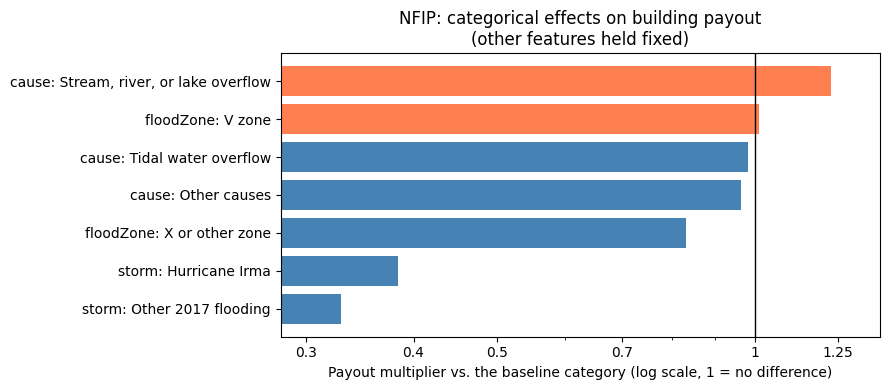

In [6]:
dummies = pd.get_dummies(data[categorical], drop_first=True, dtype=float)
print('Baseline category for each feature (folded into the intercept):',
      {c: sorted(data[c].unique())[0] for c in categorical})
X_cat = X_cont.join(dummies)
zone_d = pd.get_dummies(data[['floodZone']], drop_first=True, dtype=float)
storm_d = pd.get_dummies(data[['floodZone', 'storm']], drop_first=True, dtype=float)
results.append(evaluate('+ flood zone', X_cont.join(zone_d)))
results.append(evaluate('+ flood zone, storm', X_cont.join(storm_d)))
results.append(evaluate('+ flood zone, storm, cause of damage', X_cat))
floors_cat = pd.get_dummies(data['floors'].clip(upper=4).astype(int).astype(str), prefix='floors',
                            drop_first=True, dtype=float)
results.append(evaluate('Same, but floors as categories (1, 2, 3, 4+)', X_cat.drop(columns='floors').join(floors_cat)))
print(pd.DataFrame(results).round(4).to_string(index=False))

cat_model = LinearRegression().fit(X_cat.iloc[train_idx], y[train_idx])
cat_coefs = pd.Series(cat_model.coef_, index=X_cat.columns)[dummies.columns]
print()
print('Category effects relative to the baseline category, holding the other features fixed:')
print(pd.DataFrame({'coef (log10)': cat_coefs, 'payout multiplier': 10 ** cat_coefs}).round(3).to_string())

# The dummy variable trap: keep every category and the intercept
full_dummies = pd.get_dummies(data[categorical], dtype=float)
Z_cont = StandardScaler().fit_transform(X_cont)
X_trap = np.column_stack([np.ones(len(data)), Z_cont, full_dummies.values])
X_ok = np.column_stack([np.ones(len(data)), Z_cont, dummies.values])
print()
print(f'All {full_dummies.shape[1]} dummies plus an intercept: {X_trap.shape[1]} columns, rank {np.linalg.matrix_rank(X_trap)}')
print(f'One dummy dropped per category: {X_ok.shape[1]} columns, rank {np.linalg.matrix_rank(X_ok)}')

fig, ax = plt.subplots(figsize=(9, 4))
mult = (10 ** cat_coefs).sort_values()
labels = [n.replace('_', ': ') for n in mult.index]
ax.barh(labels, mult.values, color=np.where(mult.values > 1, 'coral', 'steelblue'))
ax.axvline(1, color='black', linewidth=1)
ax.set_xscale('log')
ticks = [0.3, 0.4, 0.5, 0.7, 1, 1.25]
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlim(0.28, 1.4)
ax.set_xlabel('Payout multiplier vs. the baseline category (log scale, 1 = no difference)')
ax.set_title('NFIP: categorical effects on building payout\n(other features held fixed)')
plt.tight_layout()
plt.show()

The storm is by far the most useful categorical feature. Adding it raises cross-validated R-squared from 0.264 to 0.311, while flood zone and cause of damage add about 0.001 and 0.004. Holding depth, building value, coverage, and the rest fixed, an Irma claim pays about 0.38 times as much as a Harvey claim and other 2017 flooding about 0.33 times as much. Flood zone barely matters once the other features are in, apart from X zones paying about 17% less than A zones. River and lake overflow pays about 23% more than rainfall accumulation.

The dummy variable trap shows up in the rank check. With all 10 dummies plus an intercept the design matrix has 20 columns but a rank of only 17, because within each categorical feature the dummies add up to exactly 1, the same as the intercept column. That is perfect multicollinearity, and the coefficients would have no unique solution. Dropping one dummy per feature brings the rank back to the number of columns.

Treating the number of floors as categories instead of a number helps a little (CV R-squared 0.315 to 0.319). The payout does not change in a straight line with the number of floors, so letting each level have its own effect fits better, at the cost of two extra columns.

### Polynomial terms in water depth

Water depth is the most direct measure of how bad the flooding was, but there is no reason to expect its effect to be a straight line. A polynomial term lets a linear regression bend. Adding $\text{depth}^2$ and $\text{depth}^3$ as extra columns still gives a model that is linear in its coefficients, so ordinary least squares fits it the same way. I centered depth on its mean before raising it to a power, which matters for multicollinearity later on. The next cell tries degrees 1 through 8, with all the other features included, and plots how each degree bends the depth effect.

                     Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
Depth polynomial, degree 1       16    0.3156 0.3151   0.3118             0.5218
Depth polynomial, degree 2       17    0.3411 0.3406   0.3360             0.5126
Depth polynomial, degree 3       18    0.3448 0.3443   0.3399             0.5111
Depth polynomial, degree 4       19    0.3448 0.3443   0.3399             0.5111
Depth polynomial, degree 5       20    0.3466 0.3461   0.3412             0.5106
Depth polynomial, degree 6       21    0.3469 0.3463   0.3411             0.5106
Depth polynomial, degree 7       22    0.3469 0.3464   0.3411             0.5106
Depth polynomial, degree 8       23    0.3469 0.3464   0.3413             0.5105


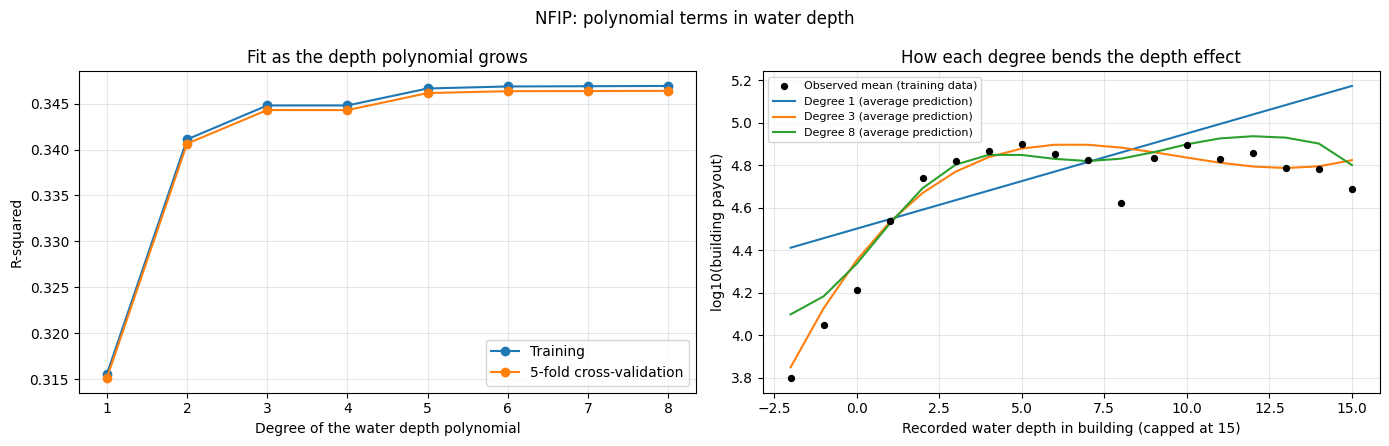

In [7]:
depth_mean = data['depth'].mean()


def with_depth_poly(X, degree):
    X = X.copy()
    for k in range(2, degree + 1):
        X[f'depth^{k}'] = (data['depth'] - depth_mean) ** k
    return X


poly_rows = [evaluate(f'Depth polynomial, degree {d}', with_depth_poly(X_cat, d)) for d in range(1, 9)]
poly_table = pd.DataFrame(poly_rows)
print(poly_table.round(4).to_string(index=False))

# Average prediction over 3,000 training claims at each depth (a partial dependence curve)
sample_index = data.index[train_idx][:3000]
grid = np.arange(-2, 16)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, 9), poly_table['Train R2'], marker='o', label='Training')
axes[0].plot(range(1, 9), poly_table['CV R2'], marker='o', label='5-fold cross-validation')
axes[0].set_xlabel('Degree of the water depth polynomial')
axes[0].set_ylabel('R-squared')
axes[0].set_title('Fit as the depth polynomial grows')
axes[0].legend()
axes[0].grid(alpha=0.3)
observed = data.iloc[train_idx].groupby(data['depth'].iloc[train_idx].round())['logPayout'].mean()
axes[1].scatter(observed.index, observed.values, color='black', s=18, zorder=3, label='Observed mean (training data)')
for d in [1, 3, 8]:
    Xd = with_depth_poly(X_cat, d)
    m = LinearRegression().fit(Xd.iloc[train_idx], y[train_idx])
    avg = []
    for dval in grid:
        Xs = Xd.loc[sample_index].copy()
        Xs['depth'] = dval
        for k in range(2, d + 1):
            Xs[f'depth^{k}'] = (dval - depth_mean) ** k
        avg.append(m.predict(Xs).mean())
    axes[1].plot(grid, avg, label=f'Degree {d} (average prediction)')
axes[1].set_xlabel('Recorded water depth in building (capped at 15)')
axes[1].set_ylabel('log10(building payout)')
axes[1].set_title('How each degree bends the depth effect')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)
fig.suptitle('NFIP: polynomial terms in water depth')
plt.tight_layout()
plt.show()

The square term does most of the work. Cross-validated R-squared goes from 0.315 with a straight line to 0.341 with degree 2 and 0.344 with degree 3, and after that it creeps up by less than 0.003 in total through degree 8. The right panel shows why. Payouts climb steeply over the first few units of depth and then level off around a depth of 5. The straight line cannot do that, so it underestimates shallow claims and overshoots deep ones by a wide margin. The cubic follows the observed means closely, and degree 8 adds wiggles at the edges (it pulls up at a depth of -2 and bumps at 12) without improving the fit. I kept degree 3.

Training and cross-validated R-squared stay almost identical for every degree, so adding depth powers is not overfitting here. With more than 75,000 training claims, eight polynomial terms are easy to estimate. The point at which polynomial terms do start to overfit comes later in the notebook.

### Interaction terms

An interaction term is the product of two features, and it lets the effect of one feature depend on the value of the other. To find out which ones are worth adding, the next cell tries every pair of features (115 pairs, skipping pairs within the same categorical feature) on top of the cubic depth model and records how much each one raises cross-validated R-squared.

In [8]:
X_poly = with_depth_poly(X_cat, 3)
base_cv = cross_val_score(LinearRegression(), X_poly.iloc[train_idx], y[train_idx], cv=kfold, scoring='r2').mean()
pairs = [(a, b) for a, b in itertools.combinations(list(X_cat.columns), 2)
         if not ('_' in a and a.split('_')[0] == b.split('_')[0])]
t0 = time.time()
gains = []
for a, b in pairs:
    X_try = X_poly.copy()
    X_try['interaction'] = X_cat[a] * X_cat[b]
    cv_r2 = cross_val_score(LinearRegression(), X_try.iloc[train_idx], y[train_idx], cv=kfold, scoring='r2').mean()
    gains.append({'Interaction': f'{a} x {b}', 'CV R2 gain': cv_r2 - base_cv})
gains = pd.DataFrame(gains).sort_values('CV R2 gain', ascending=False)
print(f'Pairs tested: {len(gains)} in {time.time() - t0:.0f} seconds | CV R2 without any interaction: {base_cv:.4f}')
print(gains.head(10).round(4).to_string(index=False))
print('Pairs that add at least 0.001 to CV R2:', int((gains['CV R2 gain'] >= 0.001).sum()))

Pairs tested: 115 in 26 seconds | CV R2 without any interaction: 0.3443
                                          Interaction  CV R2 gain
         constructionYear x elevatedBuildingIndicator      0.0132
              constructionYear x storm_Hurricane Irma      0.0071
              logCoverage x elevatedBuildingIndicator      0.0071
                 latitude x elevatedBuildingIndicator      0.0066
         constructionYear x floodZone_X or other zone      0.0049
                 latitude x storm_Other 2017 flooding      0.0046
elevatedBuildingIndicator x storm_Other 2017 flooding      0.0043
                          constructionYear x latitude      0.0042
            logReplacementCost x storm_Hurricane Irma      0.0041
                           depth x logReplacementCost      0.0041
Pairs that add at least 0.001 to CV R2: 32


                                     Model  Columns  Train R2  CV R2  Test R2  Test RMSE (log10)
                  Categories + cubic depth       18    0.3448 0.3443   0.3399             0.5111
Categories + cubic depth + year x elevated       19    0.3580 0.3575   0.3527             0.5061
Change in payout per decade of construction year, not elevated: +1.3%
Change in payout per decade of construction year, elevated: -17.6%


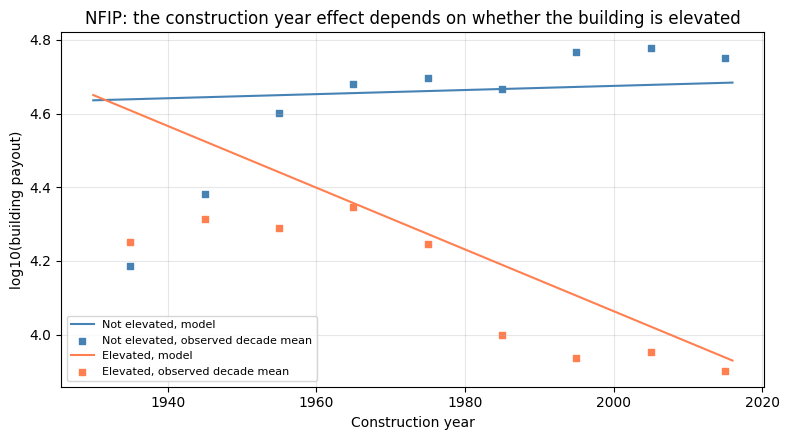

In [9]:
year_mean = data['constructionYear'].mean()
X_int = X_poly.copy()
X_int['yearCentered x elevated'] = (data['constructionYear'] - year_mean) * data['elevatedBuildingIndicator']
results.append(evaluate('Categories + cubic depth', X_poly))
results.append(evaluate('Categories + cubic depth + year x elevated', X_int))
print(pd.DataFrame(results[-2:]).round(4).to_string(index=False))

m_int = LinearRegression().fit(X_int.iloc[train_idx], y[train_idx])
c = pd.Series(m_int.coef_, index=X_int.columns)
for label, slope in [('not elevated', c['constructionYear']),
                     ('elevated', c['constructionYear'] + c['yearCentered x elevated'])]:
    print(f'Change in payout per decade of construction year, {label}: {(10 ** (10 * slope) - 1) * 100:+.1f}%')

# Average prediction across construction years for elevated and non-elevated buildings
years = np.arange(1930, 2018, 2)
sample = X_int.loc[sample_index].copy()
fig, ax = plt.subplots(figsize=(8, 4.5))
for flag, color, label in [(0, 'steelblue', 'Not elevated'), (1, 'coral', 'Elevated')]:
    avg = []
    for yr in years:
        Xs = sample.copy()
        Xs['constructionYear'] = yr
        Xs['elevatedBuildingIndicator'] = flag
        Xs['yearCentered x elevated'] = (yr - year_mean) * flag
        avg.append(m_int.predict(Xs).mean())
    ax.plot(years, avg, color=color, label=f'{label}, model')
    grp = data.iloc[train_idx]
    grp = grp[(grp['elevatedBuildingIndicator'] == flag) & (grp['constructionYear'] >= 1930)]
    decade = grp.groupby((grp['constructionYear'] // 10) * 10 + 5)['logPayout'].agg(['mean', 'size'])
    decade = decade[decade['size'] >= 100]
    ax.scatter(decade.index, decade['mean'], color=color, s=25, marker='s', label=f'{label}, observed decade mean')
ax.set_xlabel('Construction year')
ax.set_ylabel('log10(building payout)')
ax.set_title('NFIP: the construction year effect depends on whether the building is elevated')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Most single interactions add very little. Only 32 of the 115 pairs raise cross-validated R-squared by at least 0.001. The clear winner is construction year times the elevated indicator (+0.013), and the plot shows what it means. For buildings that are not elevated, newer construction makes almost no difference (+1.3% in payout per decade). For elevated buildings, every decade newer cuts the payout by about 17.6%. One likely reason is that older elevated buildings were often raised only a little or under looser rules, while elevated buildings from recent decades generally had to sit above the base flood elevation, so the water reaches less of the building. A single coefficient for construction year would average these two very different patterns and describe neither.

The observed decade means also show the limit of a straight-line interaction. Non-elevated buildings from before 1950 pay noticeably less than the model's flat line suggests, so the construction year effect itself is curved. A squared year term could be the next refinement.

### Multicollinearity and the variance inflation factor

Polynomial and interaction terms are built from the original features, so they tend to be correlated with them. The VIF measures how much a coefficient's variance is inflated because its feature can be predicted from the other features. A VIF of 1 means no overlap, and values above 5 or 10 are usually treated as a warning. The next cell computes the VIFs three ways, for the base model, with raw (uncentered) depth powers and a raw year times elevated product, and with the centered versions used above.

                                       Base model  Raw powers and product  Centered powers and product
depth                                        1.03                   24.17                         4.07
logReplacementCost                           1.25                    1.26                         1.26
logCoverage                                  1.25                    1.25                         1.25
floors                                       1.16                    1.16                         1.16
constructionYear                             1.11                    1.44                         1.44
latitude                                     1.79                    1.80                         1.80
longitude                                    2.53                    2.53                         2.53
elevatedBuildingIndicator                    1.23                 8247.26                         1.24
primaryResidenceIndicator                    1.09                    1.09

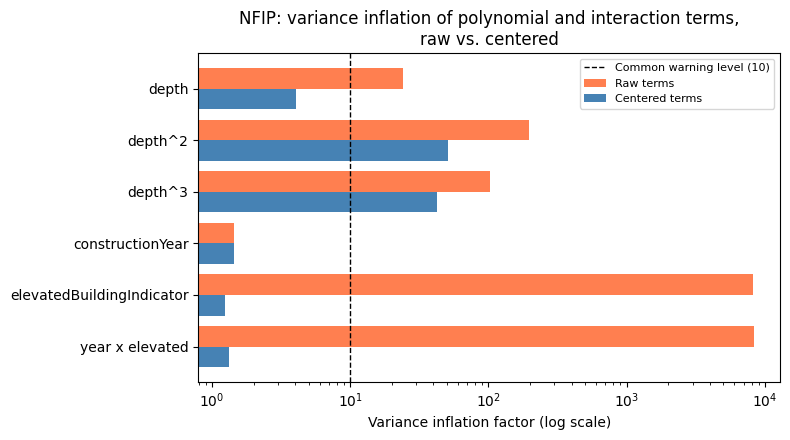

In [10]:
def vif(X):
    """Variance inflation factors from the inverse of the correlation matrix."""
    Z = (X - X.mean()) / X.std()
    return pd.Series(np.diag(np.linalg.inv(np.corrcoef(Z.values, rowvar=False))), index=X.columns)


X_raw_terms = X_cat.copy()
X_raw_terms['depth^2'] = data['depth'] ** 2
X_raw_terms['depth^3'] = data['depth'] ** 3
X_raw_terms['year x elevated'] = data['constructionYear'] * data['elevatedBuildingIndicator']
names = list(X_cat.columns) + ['depth^2', 'depth^3', 'year x elevated']
vif_compare = pd.DataFrame({'Base model': list(vif(X_cat).values) + [np.nan] * 3,
                            'Raw powers and product': vif(X_raw_terms).values,
                            'Centered powers and product': vif(X_int).values}, index=names)
print(vif_compare.round(2).to_string())

m_raw = LinearRegression().fit(X_raw_terms.iloc[train_idx], y[train_idx])
diff = np.abs(m_raw.predict(X_raw_terms.iloc[test_idx]) - m_int.predict(X_int.iloc[test_idx])).max()
print()
print(f'Largest difference between the two models\' test predictions: {diff:.2e} (log10 units)')
print(f"Correlation of depth with depth^2: raw {data['depth'].corr(data['depth'] ** 2):.3f}, "
      f"centered {data['depth'].corr((data['depth'] - depth_mean) ** 2):.3f}")
print(f"Correlation of elevated with year x elevated: raw {data['elevatedBuildingIndicator'].corr(X_raw_terms['year x elevated']):.4f}, "
      f"centered {data['elevatedBuildingIndicator'].corr(X_int['yearCentered x elevated']):.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
show = ['depth', 'depth^2', 'depth^3', 'constructionYear', 'elevatedBuildingIndicator', 'year x elevated']
pos = np.arange(len(show))
ax.barh(pos - 0.2, vif_compare.loc[show, 'Raw powers and product'], height=0.4, color='coral', label='Raw terms')
ax.barh(pos + 0.2, vif_compare.loc[show, 'Centered powers and product'], height=0.4, color='steelblue', label='Centered terms')
ax.set_yticks(pos)
ax.set_yticklabels(show)
ax.set_xscale('log')
ax.axvline(10, color='black', linestyle='--', linewidth=1, label='Common warning level (10)')
ax.invert_yaxis()
ax.set_xlabel('Variance inflation factor (log scale)')
ax.set_title('NFIP: variance inflation of polynomial and interaction terms,\nraw vs. centered')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The base model has no multicollinearity problem. The largest VIF is 2.79, for the Irma indicator, which overlaps with longitude since Irma claims are mostly in Florida.

The engineered terms are a different story. Built from raw values, the year times elevated product has a VIF of about 8,260, and the elevated indicator itself jumps from 1.23 to about 8,247. Construction year barely varies relative to its size (values near 2,000 with a spread of a few decades), so for elevated buildings the product is roughly the same number every time, and the product and the indicator have a correlation of 0.9999. Centering construction year before multiplying drops the correlation to 0.08, and both VIFs fall to about 1.3.

Centering helps the depth powers less. The VIF of $\text{depth}^2$ drops from about 198 to 51 and $\text{depth}^3$ from 103 to 42, but both stay above the warning level. Depth is skewed, with the median claim at a depth of 1 and a long tail out to 15, so even the centered square still tracks depth closely (correlation 0.85). Orthogonal polynomials or a spline would remove the rest.

The most useful line in that output is the last one. The model with raw terms and the model with centered terms make the same predictions, to within $10^{-13}$. This kind of multicollinearity comes from how the terms are written, not from the data, so it inflates the standard errors of individual coefficients and makes them hard to read, but it does not hurt prediction at all. Centering is still worth doing because it makes the main effects interpretable as effects at an average building.

### Full polynomial expansions and overfitting

Picking interactions by hand is slow, so the next cell tries the other extreme. `PolynomialFeatures` creates every square and every pairwise product of all 16 columns (152 columns at degree 2), or every cube and three-way product as well (968 columns at degree 3). The second part refits each expansion on training sets from 300 claims up to the full 75,468, to see how much data each one needs.

                                 Model  Columns  Train R2   CV R2  Test R2  Test RMSE (log10)  Seconds
Every feature, full degree-1 expansion       16    0.3156  0.3151   0.3118             0.5218        0
Every feature, full degree-2 expansion      152    0.4155  0.4010   0.4069             0.4844        5
Every feature, full degree-3 expansion      968    0.4561 -3.2690   0.4239             0.4774       39



Test R-squared by training size and degree:
Degree               1      2          3
Training claims                         
300              0.226 -6.198 -85128.243
1000             0.275 -0.109 -29949.918
3000             0.309  0.353     -5.356
10000            0.311  0.398     -9.054
30000            0.312  0.405      0.389
75468            0.312  0.407      0.424


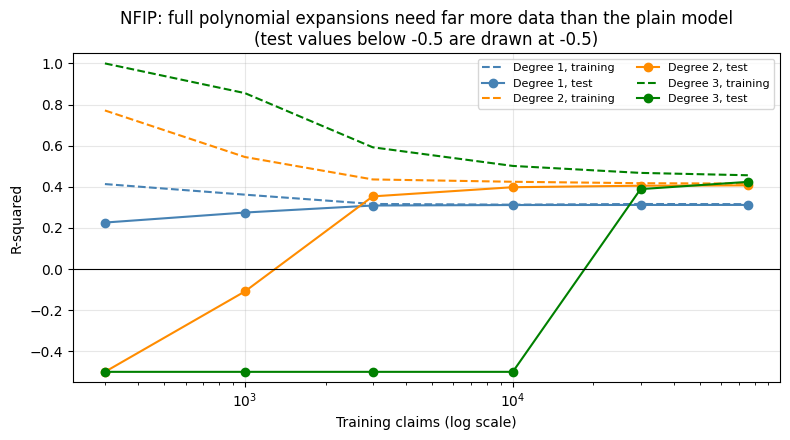

In [11]:
def poly_model(degree):
    return make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False), LinearRegression())


expansion = []
for degree in [1, 2, 3]:
    t0 = time.time()
    row = evaluate(f'Every feature, full degree-{degree} expansion', X_cat, poly_model(degree))
    row['Columns'] = PolynomialFeatures(degree, include_bias=False).fit(X_cat.iloc[:5]).n_output_features_
    row['Seconds'] = round(time.time() - t0)
    expansion.append(row)
print(pd.DataFrame(expansion).round(4).to_string(index=False))

sizes = [300, 1000, 3000, 10000, 30000, len(train_idx)]
rng = np.random.RandomState(0)
curve = []
for n in sizes:
    sub = rng.choice(train_idx, n, replace=False) if n < len(train_idx) else train_idx
    for degree in [1, 2, 3]:
        m = poly_model(degree).fit(X_cat.iloc[sub], y[sub])
        curve.append({'Training claims': n, 'Degree': degree,
                      'Train R2': r2_score(y[sub], m.predict(X_cat.iloc[sub])),
                      'Test R2': r2_score(y[test_idx], m.predict(X_cat.iloc[test_idx]))})
curve = pd.DataFrame(curve)
print()
print('Test R-squared by training size and degree:')
print(curve.pivot(index='Training claims', columns='Degree', values='Test R2').round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {1: 'steelblue', 2: 'darkorange', 3: 'green'}
for degree in [1, 2, 3]:
    part = curve[curve['Degree'] == degree]
    ax.semilogx(part['Training claims'], part['Train R2'], '--', color=colors[degree], label=f'Degree {degree}, training')
    ax.semilogx(part['Training claims'], part['Test R2'].clip(lower=-0.5), '-o', color=colors[degree], label=f'Degree {degree}, test')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylim(-0.55, 1.05)
ax.set_xlabel('Training claims (log scale)')
ax.set_ylabel('R-squared')
ax.set_title('NFIP: full polynomial expansions need far more data than the plain model\n(test values below -0.5 are drawn at -0.5)')
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Final evaluation on the held-out test set

                                     Model  Columns   CV R2
Categories + cubic depth + year x elevated       19  0.3575
    Every feature, full degree-2 expansion      152  0.4010
    Every feature, full degree-3 expansion      968 -3.2690
Chosen by cross-validation: Every feature, full degree-2 expansion



Test R2: 0.4069 | test RMSE: 0.484 log10 units (a typical miss of about 3.1x)
Share of test claims predicted within a factor of 2 of the actual payout: 0.556
Same share when every claim is predicted at the training average: 0.356


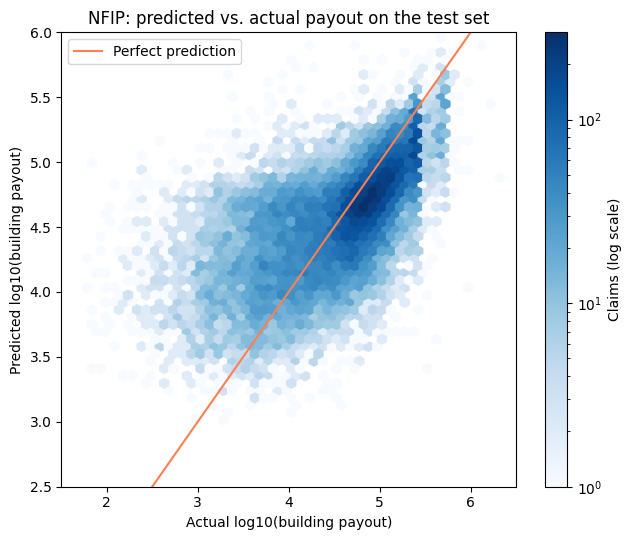

In [12]:
candidates = pd.DataFrame(results[-1:] + expansion[1:])
print(candidates[['Model', 'Columns', 'CV R2']].round(4).to_string(index=False))
best = candidates.loc[candidates['CV R2'].idxmax(), 'Model']
print('Chosen by cross-validation:', best)
final_model = poly_model(2) if 'degree-2' in best else (poly_model(3) if 'degree-3' in best else LinearRegression())
final_X = X_cat if 'expansion' in best else X_int
final_model.fit(final_X.iloc[train_idx], y[train_idx])
pred = final_model.predict(final_X.iloc[test_idx])
rmse = mean_squared_error(y[test_idx], pred) ** 0.5
ratio = 10 ** np.abs(pred - y[test_idx])
naive = np.full(len(test_idx), y[train_idx].mean())
print()
print(f'Test R2: {r2_score(y[test_idx], pred):.4f} | test RMSE: {rmse:.3f} log10 units (a typical miss of about {10 ** rmse:.1f}x)')
print(f'Share of test claims predicted within a factor of 2 of the actual payout: {(ratio <= 2).mean():.3f}')
print(f'Same share when every claim is predicted at the training average: {(10 ** np.abs(naive - y[test_idx]) <= 2).mean():.3f}')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
hb = ax.hexbin(y[test_idx], pred, gridsize=60, bins='log', cmap='Blues', mincnt=1)
lims = [1.5, 6.5]
ax.plot(lims, lims, color='coral', linewidth=1.5, label='Perfect prediction')
ax.set_xlim(lims)
ax.set_ylim(2.5, 6)
ax.set_xlabel('Actual log10(building payout)')
ax.set_ylabel('Predicted log10(building payout)')
ax.set_title('NFIP: predicted vs. actual payout on the test set')
fig.colorbar(hb, ax=ax, label='Claims (log scale)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

The full degree-2 expansion is a real improvement. Cross-validated R-squared goes from 0.358 for the hand-built model to 0.401, so the many small interactions that were not worth adding one at a time do add up. The cubic expansion is where things break. Its training R-squared is 0.456, but its cross-validated R-squared averages -3.27 over the five folds, which means at least one fold produced wildly wrong predictions for some claims. With 968 columns, a few claims with unusual combinations of feature values push the cubic terms far outside the range they were fit on.

On the held-out test set the degree-2 expansion reaches an R-squared of 0.407 and an RMSE of 0.484 in log10 units, so a typical prediction is off by a factor of about 3. It predicts 55.6% of test claims within a factor of 2 of the actual payout, compared with 35.6% when every claim is predicted at the training average. The scatter plot shows the usual pattern for a model with moderate R-squared. Predictions are pulled toward the middle, so the smallest claims are overpredicted and the largest underpredicted.

## Discussion

### Overfitting

The main protection against overfitting was choosing every model by 5-fold cross-validation on the training set and checking the final choice once on a held-out test set of 25,157 claims. That is what caught the cubic expansion. Its training R-squared was the highest of any model, and the test set alone would have made it look fine (0.424), but the cross-validated score of -3.27 showed that it is unstable and that its good test score depends on which claims happen to be in the test set.

The learning curve shows how overfitting depends on the number of columns relative to the number of claims. The plain model with 16 columns is close to its final test score by about 3,000 claims, and even with 300 claims it reaches a test R-squared of 0.23. The degree-2 expansion needs about 3,000 claims before its test score turns positive (-6.2 at 300 claims, 0.35 at 3,000), and the degree-3 expansion stays far below zero until 30,000 claims. With fewer claims than columns, the training fit is close to perfect (degree 3 reaches a training R-squared of 1.0 at 300 claims) and the test predictions are meaningless.

For the hand-built models, overfitting was never a concern. Training and cross-validated R-squared differ by less than 0.001 for every model up to 19 columns, which is what you would expect with 75,468 training claims.

### Metrics and hyperparameter tuning

R-squared on the log payout was the main metric, since it says what share of the variation in claim size the model explains and it is easy to compare across feature sets. RMSE in log10 units is reported alongside it, and converting it with $10^{\text{RMSE}}$ gives a typical multiplicative error, about 3.1 times for the final model. The share of claims predicted within a factor of 2 is the most concrete measure for anyone using the predictions.

The settings tuned here were structural choices, not hyperparameters in the usual sense. The degree of the depth polynomial was chosen by cross-validation (degree 3, where the gains stopped), the interaction was chosen by screening every pair with cross-validation, and the expansion degree for the final model was chosen the same way. In each case a higher degree or more terms means a more flexible model, and the cross-validated score is what says when the extra flexibility stops paying off.

### Expected or unexpected

I expected water depth to need a curve, since damage should rise quickly once water gets inside a building and then level off once most of the lowest floor is under water. I did not expect the storm to matter as much as it does. Holding the building and the water depth fixed, a Harvey claim still pays about 2.6 times as much as an Irma claim. One possible reason is how long the water stayed, since Harvey stalled over the Houston area and left water standing in homes for days, but the dataset has no usable flood duration field to test that (it is 0 for almost every claim).

The construction year and elevation interaction was also a surprise, mostly because of its size. Elevation already had a large effect in the base model (about 67% lower payouts), but the interaction shows that an elevated building from the 1940s performs about like a non-elevated one, while one built in the 2000s pays much less.

The most unexpected result was how badly the cubic expansion failed in cross-validation while looking fine on the test set. It is a good example of why one test score is not enough to trust a flexible model.

### How EDA helped

The Module B EDA shaped almost every choice here. The right-skew in payouts is why the target is logged. The finding that damage predicts payout almost perfectly is why damage fields were left out. The concentration of 2017 claims in Texas and Florida suggested that the storm itself would matter, which turned the `floodEvent` field into the most useful categorical feature in the notebook. The summary tables at the top of this notebook also showed that the cause of damage separated tidal claims from river claims before any model was fit.

EDA was less helpful for interactions. Nothing in the univariate or bivariate plots pointed to construction year and elevation, and it only turned up because every pair was tested.

### External sources

- scikit-learn User Guide, "Polynomial features," in the Preprocessing data chapter: https://scikit-learn.org/stable/modules/preprocessing.html#polynomial-features
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 3 ("Linear Regression"), especially the sections on qualitative predictors, interaction terms, non-linear relationships, and collinearity.
- Penn State STAT 501, "Detecting Multicollinearity Using Variance Inflation Factors" and the lesson on reducing structural multicollinearity by centering: https://online.stat.psu.edu/stat501/lesson/12
- OpenFEMA data dictionary for the FIMA NFIP Redacted Claims dataset, for the cause of damage codes and flood event names: https://www.fema.gov/openfema-data-page/fima-nfip-redacted-claims-v2

### Conclusions

Without using any damage or payout fields, a linear regression explains about 41% of the variation in log building payout for 2017 NFIP claims (test R-squared 0.407), up from 26% with continuous features alone. The gains came in three steps. The storm and the other categorical features added about 0.05, a cubic in water depth added about 0.03, and interactions added about 0.06, mostly through a full degree-2 expansion. Multicollinearity created by polynomial and interaction terms looked alarming in the VIFs (up to about 8,260), but it was an artifact of how the terms were written, and centering removed most of it without changing a single prediction.

For the Capstone, the main takeaways are that claim severity depends on the storm as well as the building, that depth needs to enter as a curve, and that the effect of elevation depends on when the building was built. The remaining 59% of unexplained variation is what the land cover and property value data in the Capstone proposal are meant to address.